In [2]:
import jax
import os

# Avoid OOM errors
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"]=".33"
# os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"]="false"
print(f"JAX backend: {jax.default_backend()}")

JAX backend: gpu


If you don't set the GPU memory allocation, then you can accidentally run out of memory. Sometimes GPU usage is persistant because notebooks, I think.

In [3]:
import sys
sys.path.append("../")

%load_ext autoreload
%autoreload 2

import pulse_simulator as ps

/home/andy/.cache/pypoetry/virtualenvs/pulse-simulator-0UjnMsVt-py3.10/lib/python3.10/site-packages/qiskit_dynamics/dispatch/backends/jax.py:34: UserWarning: The functionality in the perturbation module of Qiskit Dynamics requires a JAX version <= 0.4.6, due to a bug in JAX versions > 0.4.6. For versions 0.4.4, 0.4.5, and 0.4.6, using the perturbation module functionality requires setting os.environ['JAX_JIT_PJIT_API_MERGE'] = '0' before importing JAX or Dynamics.
  warnings.warn(


In [4]:
from datetime import datetime
import functools
import itertools
import logging
import numpy as np
import pickle as pkl
import qiskit as qk
from qiskit import pulse
import qiskit_aer
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d
import qutip as qt
import re 
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm
from tqdm import tqdm
import warnings

import matplotlib.pyplot as plt

In [5]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

backend = qk_fp.FakeManila()
dt = backend.configuration().dt * ns
desired_1qb_duration = 225  # dt
desired_2qb_duration = 225 * 4  # dt

# Gate time in SI units (granularity restriction)
duration_1qb = ps.qiskit_closest_multiple_of_16(desired_1qb_duration * dt / ns, backend)
duration_2qb = ps.qiskit_closest_multiple_of_16(desired_2qb_duration * dt / ns, backend)

# Pulses

In [7]:
qt.sigmap()

Quantum object: dims = [[2], [2]], shape = (2, 2), type = oper, isherm = False
Qobj data =
[[0. 1.]
 [0. 0.]]

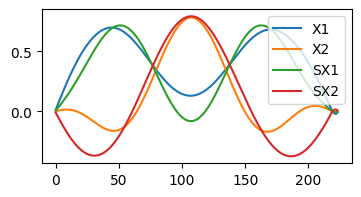

In [5]:
# Load shapes
fname = "../pico-pulses/saved-pulses-2024-01-24/a_single_qubit_gateset_R1e-3.csv"
knames = ["X1", "X2", "SX1", "SX2"]
pico_a = {k: v for k, v in zip(knames, ps.from_csv(fname))}

# The initial run takes awhile to construct the symbolic pulse shapes
x_gates = {}
for k, v in pico_a.items():
    x_gates[k] = ps.scalable_symbolic_pulse(duration_1qb, v, f"custom-{k}")

# Calibrate the robust X gates
fig, ax = plt.subplots(1, 1, figsize=[4,2])
cal_x_gates = {}
cal_values = [1.5 * np.pi, 0.5 * np.pi, 1.25 * np.pi, 0.25 * np.pi]
for θ, (k, v) in zip(cal_values, x_gates.items()):
    amp = ps.get_amplitude_for_rotation(θ, ps.get_samples(v).real, dt)
    cal_x_gates[k] = qk.pulse.ScalableSymbolicPulse(
        pulse_type=f"{k}-calibrated",
        duration=duration_1qb,
        amp=amp,
        angle=0.0,
        limit_amplitude=False,
        envelope=v.envelope,
    )
    ax.plot(ps.get_samples(v).real, label=k)
ax.legend()

# Calibrate the default X gates
default_gates = {}
for k in pico_a.keys():
    if "SX" in k:
        default_gates[k] = ps.gaussian_envelope(duration_1qb, dt=dt, angle=np.pi / 4)
    else:
        default_gates[k] = ps.gaussian_envelope(duration_1qb, dt=dt, angle=np.pi / 2)


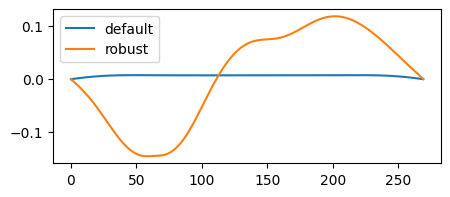

In [6]:
# Load shapes
def fname(k):
    return f"../pico-pulses/saved-pulses-2024-01-16/a_two_qubit_{k}.csv"
knames = ["default", "robust"]
pico2_a = {k: ps.from_csv(fname(k))[0] for k in knames}

# Less precise about optimization than before...
fig, ax = plt.subplots(figsize=[5, 2])
for k, v in pico2_a.items():
    ax.plot(v, label=k)
ax.legend()

# Downsample the pulse to make construction faster
cr_gates = {}
for k, v in pico2_a.items():
    cr_gates[k] = ps.scalable_symbolic_pulse(
        duration_2qb,
        ps.resample(51, v, keep_step=False),
        f"cr-{k}"
    )

# Add positive and negative rotations to gateset
cal_cr_gates = {}
cal_values = [0.125 * np.pi, 0.125 * np.pi]
for θ, (k, v) in zip(cal_values, cr_gates.items()):
    amp = ps.get_amplitude_for_rotation(θ, ps.get_samples(v).real, dt)
    cal_cr_gates[k] = {
        "+": qk.pulse.ScalableSymbolicPulse(
            pulse_type=f"{k}-calibrated+amp",
            duration=duration_2qb,
            amp=amp,
            angle=0.0,
            limit_amplitude=False,
            envelope=v.envelope,
        ),
        "-": qk.pulse.ScalableSymbolicPulse(
            pulse_type=f"{k}-calibrated-amp",
            duration=duration_2qb,
            amp=-amp,
            angle=0.0,
            limit_amplitude=False,
            envelope=v.envelope,
        ),
    }

# Circuits

In [7]:
# Set the parameters globally for the model
N = 4  # number of spins
hz = 1.0 * 2 * np.pi  # magnetic field along z
Jx = 1.0 * 2 * np.pi  # Coupling along x
Δt = 0.05  # time step for integration


def create_initial_state(qr, cr):
    '''
    Creates the initial state for the experiment.
    Here we would like to prepare the |+>|+>|+>|+> state.
    '''
    circ = qk.QuantumCircuit(qr, cr)
    [circ.h(qr[i]) for i in range(qr.size)]
    return circ


def rxx(circ, θx, q1, q2):
    '''
    Implements the exp(-i theta/2 sx_1 sx_2) gate.
    '''
    circ.cx(q1, q2)
    circ.rx(θx, q1)
    circ.cx(q1, q2)
    return circ


def first_order_Trotter_unitary(circ, Δt, barrier=False):
    '''
    Applies a Unitary for a single time step U(Δt) using first-order trotter expansion to the input quantum circuit.
    input : circ is a quantum circuit
    output : circ-U(Δt)-
    '''
    # Layer A: coupling XX between n and n+1
    # Induce parallel CR gates
    if barrier:
        circ.barrier()
    for p in range(0, circ.num_qubits - 1, 2):
        circ = rxx(circ, Jx * Δt, circ.qubits[p], circ.qubits[p + 1])
    if barrier:
        circ.barrier()
    for p in range(1, circ.num_qubits - 1, 2):
        circ = rxx(circ, Jx * Δt, circ.qubits[p], circ.qubits[p + 1])

    #  Alt., a naive loop will apply XX rotations sequentially, failing to stack.
    # for p in range(0, circ.num_qubits - 1):
    #     circ = rxx(circ, Jx * Δt, circ.qubits[p], circ.qubits[p + 1])

    # Layer B: on-site Z
    for p in range(circ.num_qubits):    
        circ.rz(hz*Δt, circ.qubits[p])

    return circ


def second_order_Trotter_unitary(circ, Δt, barrier=False):
    '''
    Applies a Unitary for a single time step U(Δt) using second-order trotter expansion to the input quantum circuit.
    input : circ is a quantum circuit
    output : circ-U(Δt)-
    '''
    # Layer 2: on-site Z (half)
    for p in range(circ.num_qubits):
        circ.rz(hz * Δt / 2, circ.qubits[p])
 
    # Layer 1: coupling XX between n and n+1
    # Induce parallel structure (and symmetry)
    for p in range(1, circ.num_qubits - 1, 2):
        circ = rxx(circ, Jx * Δt / 2, circ.qubits[p], circ.qubits[p+1])
    # NOTE: Add barriers to separate the parallel section
    if barrier:
        circ.barrier()
    for p in range(0, circ.num_qubits - 1, 2):
        circ = rxx(circ, Jx * Δt, circ.qubits[p], circ.qubits[p+1])
    if barrier:
        circ.barrier()
    for p in range(1, circ.num_qubits - 1, 2):
        circ = rxx(circ, Jx * Δt / 2, circ.qubits[p], circ.qubits[p+1])

    # Layer 2: on-site Z (half)
    for p in range(circ.num_qubits):
        circ.rz(hz * Δt / 2, circ.qubits[p])
    return circ

The circuit is 11 layers deep. Let's just play 11 layers of 4 qubits of X gates.

# Models

In [244]:
250 / μs * ns

250000.0

In [245]:
dt

0.2222222222222222

In [229]:
# Set registers above with circuit
# The rest is automatic
# =====================

# NOTE: If the Rabi rates are True, you have to calibrate!
cvars = ps.backend_simulation_vars(backend, rabi=False, units=Units)

# Change T1 and T2 to match Eagle processors like Sherbrooke
for k, v in cvars.items():
    if "t1" in k:
        cvars[k] = 250 / μs * ns
    if "t2" in k:
        cvars[k] = 150 / μs * ns

# Carrier frequencies of each control line
# NOTE: We won't use carriers in this example
carriers = ps.backend_carriers(backend, cvars)

# Partially compile model functions with parameters
# =====
H_rx = functools.partial(
    ps.rx_model,
    registers=registers,
    backend=backend,
    variables=cvars,
    rotating_frame=True,
)

H_rz = functools.partial(
    ps.rz_model,
    registers=registers,
    backend=backend,
)

H_cr = functools.partial(
    ps.cross_resonance_model,
    registers=registers,
    backend=backend,
    variables=cvars,
    model_name="Toy",
)

A_decay = functools.partial(ps.qubit_decay_model, registers=registers, variables=cvars)

edges = ps.backend_edges(backend)[1:-1]
print(f"Edges: {edges}")
H_xtalk = ps.crosstalk_model(registers, edges, cvars)

# Create a system model
# =====
H_drift = 0.0
Hs_control = []
Hs_channels = []
As_static = []
for qubit in registers:
    # Single qubit terms
    Hj_drift, Hjs_control, Hjs_channel = H_rx(qubit)
    Hj_phase, Hj_phase_ch = H_rz(qubit)
    Ajs_static = A_decay(qubit)

    H_drift += Hj_drift
    Hs_control += Hjs_control + [Hj_phase]
    Hs_channels += Hjs_channel + [Hj_phase_ch]
    As_static += Ajs_static

    # Two qubit with ring connectivity
    if qubit < len(registers) - 1:
        control, target = qubit, qubit + 1
        
        # Get both directions
        for pair in [(control, target), (target, control)]:
            Hj_drift, Hjs_control, Hjs_channel = H_cr(pair)
            H_drift += Hj_drift
            Hs_control += Hjs_control
            Hs_channels += Hjs_channel

# Some models may repeat control channels
# NOTE: This actually really matters! Repeat channels mess things up.
Hs_channels, indices = np.unique(Hs_channels, return_index=True)
Hs_control = [Hs_control[i] for i in indices]

# For RWA / Rotating frame
# NOTE: We won't use carriers in this example
# =====
registered_carriers = {c: 0 for c in Hs_channels}
cutoff_freq = None

# registered_carriers = {c: carriers[c] for c in Hs_channels}
# cutoff_freq = 2 * np.mean(list(registered_carriers.values()))

Edges: [(1, 2), (2, 3)]


In [243]:
np.max(np.abs(ps.crosstalk_model(registers, [(3,4)], cvars))) / 2 / np.pi * 1e3

0.0

In [230]:
sched = ps.build_pulse_schedule(
    my_moments,
    qubit_gates=default_gates,
    cr_gates=cal_cr_gates['default'],
    registers=registers,
    backend=backend,
    name="hamiltonian-simulation",
    dt=dt
)

robust_sched = ps.build_pulse_schedule(
    my_moments,
    qubit_gates=cal_x_gates,
    cr_gates=cal_cr_gates['robust'],
    registers=registers,
    backend=backend,
    name="hamiltonian-simulation",
    dt=dt
)

mix_sched = ps.build_pulse_schedule(
    my_moments,
    qubit_gates=default_gates,
    cr_gates=cal_cr_gates['robust'],
    registers=registers,
    backend=backend,
    name="hamiltonian-simulation",
    dt=dt
)

# Check durations
assert robust_sched.duration == sched.duration

# Would be nice to disable phase channels when plotting
# sched.draw()

# Solvers

In [231]:
# Models already in the rotating frame
# =====

solver_r0 = qk_d.Solver(
    static_hamiltonian=None,
    hamiltonian_operators=Hs_control,
    hamiltonian_channels=Hs_channels,
    # static_dissipators=As_static,
    rotating_frame=None,
    rwa_cutoff_freq=None,
    channel_carrier_freqs=registered_carriers,
    dt=dt
)

solver_r = qk_d.Solver(
    static_hamiltonian=None,
    hamiltonian_operators=Hs_control,
    hamiltonian_channels=Hs_channels,
    static_dissipators=As_static,
    rotating_frame=None,
    rwa_cutoff_freq=None,
    channel_carrier_freqs=registered_carriers,
    dt=dt
)

solver_rx0 = qk_d.Solver(
    static_hamiltonian=H_xtalk,
    hamiltonian_operators=Hs_control,
    hamiltonian_channels=Hs_channels,
    # static_dissipators=As_static,
    rotating_frame=None,
    rwa_cutoff_freq=None,
    channel_carrier_freqs=registered_carriers,
    dt=dt
)

solver_rx = qk_d.Solver(
    static_hamiltonian=H_xtalk,
    hamiltonian_operators=Hs_control,
    hamiltonian_channels=Hs_channels,
    static_dissipators=As_static,
    rotating_frame=None,
    rwa_cutoff_freq=None,
    channel_carrier_freqs=registered_carriers,
    dt=dt
)

# Unitary simulations

In [232]:
# measure after each moment
measure_times = dt * np.cumsum(
    durations_of_moments(my_moments, cal_x_gates, cal_cr_gates['default'])
)[[ps.get_moment_case(m) == "ecr" for m in my_moments]]


# targets at measure times
Uts = []
for i, m in enumerate(my_moments):
    if ps.get_moment_case(m) == "ecr":
        Uts.append(ps.build_operator(my_moments[0:i+1], registers))

In [235]:
print("Case 2: Crosstalk, no decay")

y0 = ps.qiskit_identity_operator(len(registers))

# labels = ["robust (rotary)"]
# all_schedules = [robust_sched]

labels = ["robust (rotary)",  "default (rotary)"]
all_schedules = [robust_sched, mix_sched]

# labels = ["default", "robust (rotary)", "default (rotary)"]
# all_schedules = [sched, robust_sched, mix_sched]


# ==========

solver_rx0.model.evaluation_mode = "dense"
res_x0 = solver_rx0.solve(
    t_span=[0.0, sched.duration * dt],
    t_eval=measure_times,
    y0=y0,
    signals=all_schedules,
    atol=1e-9,
    rtol=1e-9,
    method="jax_odeint",
)

# Compute fidelity (we can use our circuit to compute the target)
target = qk.quantum_info.Operator(ps.build_circuit(my_moments, registers))

for i, ell in enumerate(labels):
    print(f"\tInfidelity of {ell}: ", 1 - qk.quantum_info.process_fidelity(res_x0[i].y[-1], target))

Case 2: Crosstalk, no decay
	Infidelity of robust (rotary):  0.0005530360321340799
	Infidelity of default (rotary):  0.0005904624225901989


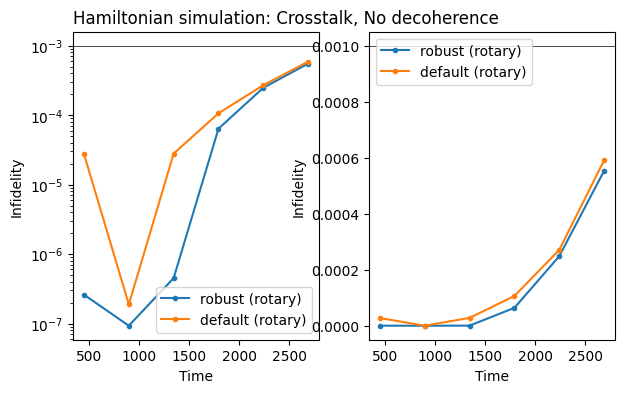

In [236]:
fig, axes = plt.subplots(1,2, figsize=[7, 4])#, dpi=300)
axes = axes if isinstance(axes, np.ndarray) else [axes]
axes[0].set_title("Hamiltonian simulation: Crosstalk, No decoherence", loc='left')


for iax in range(2):
    ax = axes[iax]

    for i, r in enumerate(res_x0):
        infids = []
        for r, t in zip(r.y, Uts):
            infids.append(1 - qk.quantum_info.process_fidelity(qk.quantum_info.Operator(r), qk.quantum_info.Operator(t)))
        ax.plot(measure_times, infids, label=labels[i], marker=".")

    # ax.axhline(0.1, color="black", linestyle="-", lw=0.5)
    # ax.axhline(0.01, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.001, color="black", linestyle="-", lw=0.5)

    ax.set_xlabel("Time")
    if iax == 0:
        ax.legend(loc="lower right")
        ax.set_yscale("log")
        ax.set_ylabel("Infidelity")
    else:
        ax.set_ylabel("Infidelity")
        ax.legend(loc="upper left")
        ax.set_yscale("linear")

### Plots for layers of Hamiltonian simulation

This is the crosstalk-free sim and plot. We won't need that sim for now.

This is the plot for the crosstalk example. We're still using that simulation up above.

 -4.78904758e-08 -4.57177030e-08 -4.04941966e-08 -3.77410569e-08
 -3.52940962e-08 -3.37060070e-08 -3.04122476e-08 -2.79739524e-08
 -2.51159524e-08 -2.17289980e-08 -1.96036072e-08 -1.48779095e-08]


 -1.00832220e-07 -9.44438767e-08 -9.16488791e-08 -8.40571370e-08
 -7.54219709e-08 -6.95856710e-08 -6.67761546e-08 -6.18477632e-08
 -5.53947669e-08 -5.09894639e-08 -4.72000857e-08 -4.08486479e-08]
 -1.45817155e-07 -1.39606176e-07 -1.35673883e-07 -1.26181450e-07
 -1.14225621e-07 -1.04909851e-07 -1.00737364e-07 -9.41078250e-08
 -8.41007160e-08 -7.91705815e-08 -7.13837359e-08 -6.11226227e-08]
 -1.99073765e-07 -1.88665514e-07 -1.81584202e-07 -1.68735847e-07
 -1.51816809e-07 -1.43614684e-07 -1.38928220e-07 -1.27490254e-07
 -1.14554565e-07 -1.06202305e-07 -9.59241924e-08 -8.66829059e-08]
 -2.42641461e-07 -2.36117964e-07 -2.22419167e-07 -2.11321857e-07
 -1.91287405e-07 -1.83151904e-07 -1.75062647e-07 -1.62744782e-07
 -1.44581928e-07 -1.36738311e-07 -1.21608299e-07 -1.10661781e-07]
 -2.90316561e-07 -2.82516399e-07 -2.68940329e-07 -2.50336355e-07
 -2.28639851e-07 -2.25599095e-07 -2.14692916e-07 -1.97077387e-07
 -1.75951858e-07 -1.66469500e-07 -1.46884568e-07 -1.37505973e-07]
 -3.30614176e-07 -3.

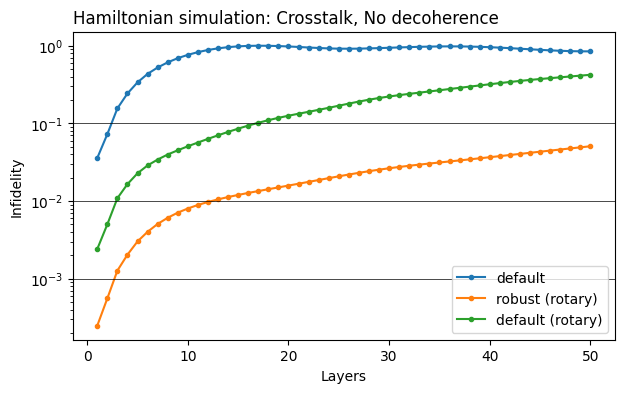

In [155]:
n = 50

fig, axes = plt.subplots(1, figsize=[7, 4])#, dpi=300)
axes = axes if isinstance(axes, np.ndarray) else [axes]
# fig.suptitle("Hamiltonian simulation: Crosstalk, No decoherence")
axes[0].set_title("Hamiltonian simulation: Crosstalk, No decoherence", loc='left')

layers = np.arange(1, n + 1)
Uts = list(itertools.accumulate(np.repeat([target], n, axis=0), np.matmul))

labels = ["default", "robust (rotary)", "default (rotary)"]

for iax in range(1):
    ax = axes[iax]

    for i, r in enumerate(res_x0):
        Ufs = itertools.accumulate(np.repeat([r.y[-1]], n, axis=0), np.matmul)
        infids = []
        for r, t in zip(Ufs, Uts):
            infids.append(1 - qk.quantum_info.process_fidelity(qk.quantum_info.Operator(r), qk.quantum_info.Operator(t)))
        ax.plot(layers, infids, label=labels[i], marker=".")

    ax.axhline(0.1, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.01, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.001, color="black", linestyle="-", lw=0.5)

    ax.set_xlabel("Layers")
    if iax == 0:
        ax.legend(loc="lower right")
        ax.set_yscale("log")
        ax.set_ylabel("Infidelity")
    else:
        ax.set_ylabel("Infidelity")
        ax.legend(loc="upper left")
        ax.set_yscale("linear")

### With decoherence

In [156]:
print("Case 3: Crosstalk and Decoherence")

y0 = ps.qiskit_identity_operator(len(registers), open=True)

solver_rx.model.evaluation_mode = "dense_vectorized"
res_x = solver_rx.solve(
    t_span=[0.0, sched.duration * dt],
    t_eval=measure_times,
    y0=y0,
    signals=[sched, robust_sched, mix_sched],
    atol=1e-9,
    rtol=1e-9,
    method="jax_odeint",
)

# Compute fidelity (we can use our circuit to compute the target)
target = qk.quantum_info.Operator(ps.build_circuit(my_moments, registers))

print(
    "\tInfidelity of default schedule: ",
    1 - qk.quantum_info.process_fidelity(res_x[0].y[-1], target),
)
print(
    "\tInfidelity of robust schedule: ",
    1 - qk.quantum_info.process_fidelity(res_x[1].y[-1], target),
)
print(
    "\tInfidelity of mixed schedule: ",
    1 - qk.quantum_info.process_fidelity(res_x[2].y[-1], target),
)

Case 3: Crosstalk and Decoherence
	Infidelity of default schedule:  0.08828993986019185
	Infidelity of robust schedule:  0.05473564664294672
	Infidelity of mixed schedule:  0.05678015387388502


In [159]:
# # Save the results
# pkl.dump(
#     {
#         "res_x0": res_x0,
#         "res_x": res_x,
#         "measure_times": measure_times,
#         "Uts": Uts,
#     },
#     open("../playground/24_02_16-crosstalk-decoherence.pkl", "wb"),
# )

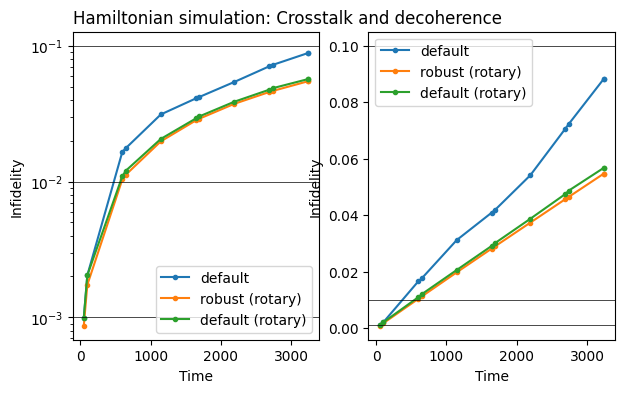

In [167]:
fig, axes = plt.subplots(1,2, figsize=[7, 4])#, dpi=300)
axes = axes if isinstance(axes, np.ndarray) else [axes]
axes[0].set_title("Hamiltonian simulation: Crosstalk and decoherence", loc='left')
labels = ["default", "robust (rotary)", "default (rotary)"]


# targets at measure times
Uts = []
for i, m in enumerate(my_moments):
    if ps.get_moment_case(m) == "single":
        Uts.append(ps.build_operator(my_moments[0:i+1], registers))
# and at the end time...
Uts.append(qk.quantum_info.Operator(ps.build_circuit(my_moments, registers)))


for iax in range(len(axes)):
    ax = axes[iax]

    for i, r in enumerate(res_x):
        infids = []
        for r, t in zip(r.y, Uts):
            infids.append(1 - qk.quantum_info.process_fidelity(qk.quantum_info.SuperOp(r), qk.quantum_info.Operator(t)))
        ax.plot(measure_times, infids, label=labels[i], marker=".")

    ax.axhline(0.1, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.01, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.001, color="black", linestyle="-", lw=0.5)

    ax.set_xlabel("Time")
    if iax == 0:
        ax.legend(loc="lower right")
        ax.set_yscale("log")
        ax.set_ylabel("Infidelity")
    else:
        ax.set_ylabel("Infidelity")
        ax.legend(loc="upper left")
        ax.set_yscale("linear")

/home/andy/.cache/pypoetry/virtualenvs/pulse-simulator-0UjnMsVt-py3.10/lib/python3.10/site-packages/qiskit/quantum_info/operators/measures.py:399: UserWarning: Treating array input as a SuperOp object
  warnings.warn(f"Treating array input as a {fallback_class.__name__} object")


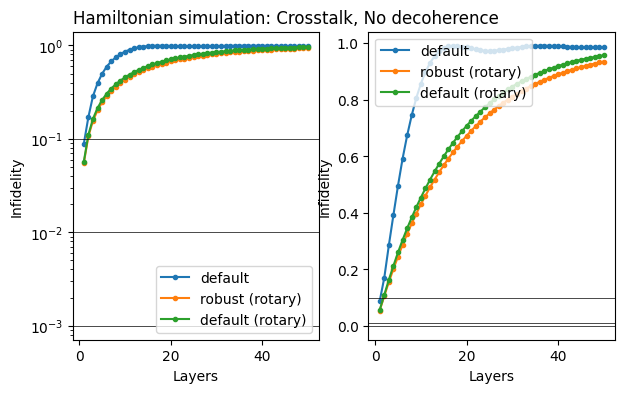

In [164]:
n = 50

fig, axes = plt.subplots(1, 2, figsize=[7, 4])#, dpi=300)
axes = axes if isinstance(axes, np.ndarray) else [axes]
# fig.suptitle("Hamiltonian simulation: Crosstalk and decoherence")
axes[0].set_title("Hamiltonian simulation: Crosstalk, No decoherence", loc='left')

layers = np.arange(1, n + 1)
Uts = list(itertools.accumulate(np.repeat([target], n, axis=0), np.matmul))

labels = ["default", "robust (rotary)", "default (rotary)"]

for iax in range(len(axes)):
    ax = axes[iax]

    for i, r in enumerate(res_x):
        Ufs = itertools.accumulate(np.repeat([r.y[-1]], n, axis=0), np.matmul)
        infids = []
        for r, t in zip(Ufs, Uts):
            infids.append(1 - qk.quantum_info.process_fidelity(r, qk.quantum_info.Operator(t)))
        ax.plot(layers, infids, label=labels[i], marker=".")

    ax.axhline(0.1, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.01, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.001, color="black", linestyle="-", lw=0.5)

    ax.set_xlabel("Layers")
    if iax == 0:
        ax.legend(loc="lower right")
        ax.set_yscale("log")
        ax.set_ylabel("Infidelity")
    else:
        ax.set_ylabel("Infidelity")
        ax.legend(loc="upper left")
        ax.set_yscale("linear")

QiskitError: 'Input quantum channel and target unitary must have the same dimensions ((256, 256) != (16, 16)).'

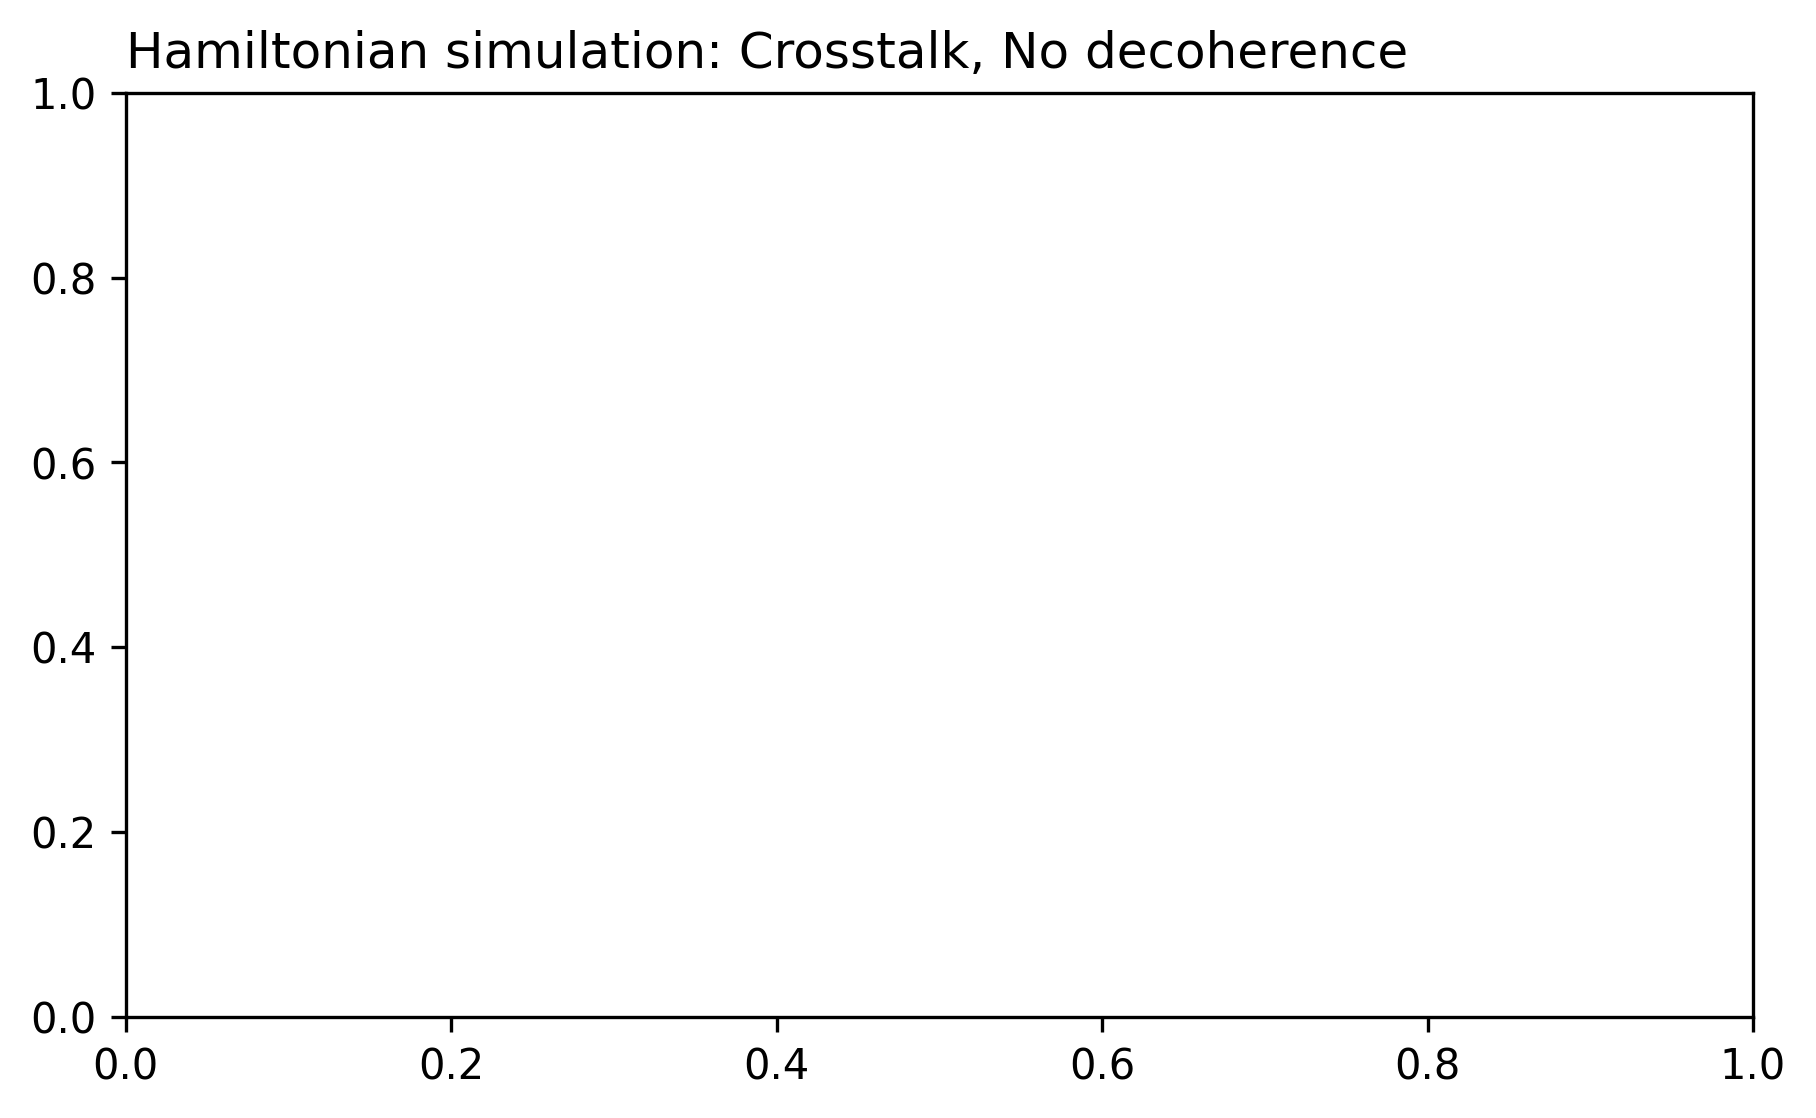

In [157]:
n = 35

fig, axes = plt.subplots(1, figsize=[7, 4])#, dpi=300)
axes = axes if isinstance(axes, np.ndarray) else [axes]
# fig.suptitle("Hamiltonian simulation: Crosstalk, No decoherence")
axes[0].set_title("Hamiltonian simulation: Crosstalk, No decoherence", loc='left')

layers = np.arange(1, n + 1)
Uts = list(itertools.accumulate(np.repeat([target], n, axis=0), np.matmul))

labels = ["default", "robust", "default (rotary)"]

for iax in range(1):
    ax = axes[iax]

    for i, r in enumerate(res_x):
        Ufs = itertools.accumulate(np.repeat([r.y[-1]], n, axis=0), np.matmul)
        infids = []
        for r, t in zip(Ufs, Uts):
            infids.append(1 - qk.quantum_info.process_fidelity(qk.quantum_info.Operator(r), qk.quantum_info.Operator(t)))
        ax.plot(layers, infids, label=labels[i], marker=".")

    ax.axhline(0.1, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.01, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.001, color="black", linestyle="-", lw=0.5)

    ax.set_xlabel("Layers")
    if iax == 0:
        ax.legend(loc="lower right")
        ax.set_yscale("log")
        ax.set_ylabel("Infidelity")
    else:
        ax.set_ylabel("Infidelity")
        ax.legend(loc="upper left")
        ax.set_yscale("linear")